# 1. Data Extraction

In [1]:
# Imports
import os
import pandas as pd
import numpy as np

import json

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import LabelEncoder

mpl.rcParams['figure.figsize'] = (10, 5)
mpl.rcParams['axes.grid'] = False


In [2]:
update_files = False

In [3]:
# global ModBus1_info,ModBus15_info,ModBus1_units,ModBus15_units,ModBus1_address
# global ModBus15_address,ModBus1_UnitDivision,ModBus15_UnitDivision,ADC_info

ModBus1_info = ['Z-Axis RMS Velocity(in/sec)','Z-Axis RMS Velocity(mm/sec)','Temperature(DegF)','Temperature(DegC)','X-Axis RMS Velocity(in/sec)',
                'X-Axis RMS Velocity(mm/sec)','Z-Axis Peak Acceleration(G)','X-Axis Peak Acceleration(G)','Z-Axis Peak Velocity Component Frequency(Hz)','X-Axis Peak Velocity Component Frequency(Hz)',
                'Z-Axis RMS Acceleration(G)','X-Axis RMS Acceleration(G)','Z-Axis Kurtosis','X-Axis Kurtosis','Z-Axis Crest Factor',
                'X-Axis Crest Factor','Z-Axis Peak Velocity(in/sec)', 'Z-Axis Peak Velocity(mm/sec)','X-Axis Peak Velocity(in/sec)', 'X-Axis Peak Velocity(mm/sec)',
                'Z-Axis High-Frequency RMS Acceleration(G)','Z-Axis High-Frequency RMS Acceleration(G)']

ModBus15_info = ['RMS Voltage L1(Volts)','RMS Voltage L2(Volts)','RMS Voltage L3(Volts)','RMS Current L1(Amps)','RMS Current L2(Amps)',
                'RMS Current L3(Amps)','Phase Shift L1(Degrees)','Phase Shift L2(Degrees)','Phase Shift L3(Degrees)','Frequency L1 Current(Hz)',
                'Frequency L2 Current','Frequency L3 Current(Hz)','Frequency L1 Voltage(Hz)','Frequency L1 Voltage(Hz)','Frequency L1 Voltage(Hz)',
                '15V sense','VIN sense']

ModBus1_units = ['in/sec','mm/sec','DegF','DegC','in/sec',
                'mm/sec','G','G','Hz','Hz',
                'G','G','Kurtosis','Kurtosis','Crest Factor',
                'Crest Factor','in/sec','mm/sec','in/sec','mm/sec',
                'G','G']

ModBus15_units = ['volts','volts','volts','Amps','Amps',
                'Amps','Degrees','Degrees','Degrees','Hz',
                'Hz','Hz','Hz','Hz','Hz',
                'millivolts','millivolts']

ADC_info = ['GND','Temp1(DegC)','Temp2(DegC)','Temp3(DegC)','NAN',
                'NAN','NAN','NAN','NAN','NAN',
                'NAN','NAN','NAN','NAN','NAN']

ModBus1_address = ["405201", "405202", "405203", "405204", "405205", 
                   "405206", "405207", "405208", "405209", "405210", 
                   "405211", "405212", "405213", "405214", "405215", 
                   "405216", "405217", "405218", "405219", "405220",
                     "405221", "405222"]

ModBus15_address = ["300001", "300002", "300003", "300004", "300005", 
                   "300006", "300007", "300008", "300009", "300010", 
                   "300011", "300012", "300013", "300014", "300015",
                     "300016", "300017"]

ModBus1_UnitDivision = [10000,1000,100,100,10000,
                        1000,1000,1000,10,10,
                        1000,1000,1000,1000,1000,
                        1000,10000,1000,10000,1000,
                        1000,1000]

ModBus15_UnitDivision = [100,100,100,100,100,
                        100,100,100,100,100,
                        100,100,100,100,100,
                        1,1]


In [4]:
def access_dir(data_sub_dir, data_dir):
    """
    Function is to generate dataset directory path based on the user defined process setting
    This is the primary acquired data directory (raw) 
    :param data_sub_dir # Choose the sub folder to get access to the desired dataset
    :param data_dir: # Choose the end directory containing desired data  
    :return: directory to access data
    """
    # get current directory
    currentpath = os.getcwd()
    # get parent data directory
    data_par_dir = os.path.abspath(os.path.join(currentpath, os.pardir))
    
    # Get the path to image dataset based on choices    
    d_dir = os.path.join(data_par_dir, (data_sub_dir + "/" + data_dir))
    
    return d_dir

def read_json_file(file):
    with open(file, "r") as r:
        response = r.read()
        response = response.replace('\n', '')
        response = response.replace('}{', '},{')
        response = "[" + response + "]"
        return json.loads(response)


def get_sensor_measurements(JSONLog,ADCSelect,ModBus1Select,ModBus15Select):
    
    # For each measurment sample, desired parameters are extracted with its corresponding units
    # selection of parameter is possible with user inputs
    ModBus1_val = []
    ModBus15_val = []
    ADCvalue = []
    
    # additional info
    ModBus1_unitsSelect =[]
    ModBus15_unitsSelect =[]
    ADC_unitSelect = []
    
    # get the time stamp for the measurements
    TimeStamp = JSONLog.get('timeStamp')[:-7]

    # get ADC sensor values
    if len(ADCSelect) == 1:
        ADCvalue = JSONLog.get('sensors').get('adc')[ADCSelect[0]]
        #ADC_unitSelect = ['DegC']
    else:
        for ADCIter in ADCSelect:
            ADCvalue.append(JSONLog.get('sensors').get('adc')[ADCIter])
            #ADC_unitSelect.append('DegC')
    
    # get ModBus sensor values - channel 1
    if len(ModBus1Select) == 1:
        ModBus1_tempval = JSONLog.get('sensors').get('modbus').get('1').get(ModBus1Select[0])        
        ModBus1_val.append(ModBus1_tempval/ModBus1_UnitDivision[ModBus1_address.index(ModBus1Select[0])])
        #ModBus1_unitsSelect.append(ModBus1_units[ModBus1_address.index(ModBus1Select[0])])
    
    else:
        for busIter in ModBus1Select:            
            ModBus1_tempval = JSONLog.get('sensors').get('modbus').get('1').get(busIter)
            ModBus1_val.append(ModBus1_tempval/ModBus1_UnitDivision[ModBus1_address.index(busIter)])  
            #ModBus1_unitsSelect.append(ModBus1_units[ModBus1_address.index(busIter)])
    
    # get ModBus sensor values - channel 15
    if len(ModBus15Select) == 1:
        ModBus15_tempval = JSONLog.get('sensors').get('modbus').get('15').get(ModBus15Select[0])        
        ModBus15_val.append(ModBus15_tempval/ModBus15_UnitDivision[ModBus1_address.index(ModBus15Select[0])])
        #ModBus15_unitsSelect.append(ModBus15_units[ModBus1_address.index(ModBus15Select[0])])
    else:
        for busIter in ModBus15Select:            
            ModBus15_tempval = JSONLog.get('sensors').get('modbus').get('15').get(busIter)
            ModBus15_val.append(ModBus15_tempval/ModBus15_UnitDivision[ModBus15_address.index(busIter)])
            #ModBus15_unitsSelect.append(ModBus15_units[ModBus15_address.index(busIter)]) 
    
    return ADCvalue,ModBus1_val,ModBus15_val,TimeStamp


def extractFeatures_toCSV(dataPath,dataSample,ADCSelect,ModBus1Select,ModBus15Select):

    # Extract individual features and save them as csv
    # Load the first json file for extracting available signals/feature list
    JsonF = os.path.join((dataPath+ "/") + dataSample)
    JsonF = read_json_file(file=JsonF)   

    # get the choosen parameter details
    #ModBus1_unitsSelected = [ModBus1_units[ModBus1_address.index(i)] for i in ModBus1Select]
    #ModBus15_unitsSelected = [ModBus15_units[ModBus15_address.index(i)] for i in ModBus15Select]
    ModBus1_infoSelected = [ModBus1_info[ModBus1_address.index(i)] for i in ModBus1Select]
    ModBus15_infoSelected = [ModBus15_info[ModBus15_address.index(i)] for i in ModBus15Select]
    ADC_infoSelected = [ADC_info[i] for i in ADCSelect]

    timeD = []
    ADCval = []
    Mod1val = []
    Mod15val = []

    # gather sensor measurements
    for i in range(len(JsonF)):
        JSONLog = JsonF[i]      
        # check if all the registers are logged for each measurments.
        # otherwise skip them for adding to the log
        # some measurements does not include all the registers for some reason
        if all(key in JSONLog['sensors']['modbus']['1'].keys() for key in ModBus1Select):
            if all(key in JSONLog['sensors']['modbus']['15'].keys() for key in ModBus15Select):
                A,B,C,D = get_sensor_measurements(JSONLog,ADCSelect,ModBus1Select,ModBus15Select)
        else:
            continue
        
        # append each measurement in a list
        timeD.append(D)
        ADCval.append(np.round(A,2))
        Mod1val.append(B)
        Mod15val.append(C)

    # create a pandas dataframe for all the measurements
    df = pd.DataFrame(ADCval, columns = [ADC_infoSelected]) 
    df[ModBus1_infoSelected] = Mod1val
    df[ModBus15_infoSelected] = Mod15val
    df.insert (0,'TimeStamp',timeD)
    
    # returns JSON object as a dictionary      
    return df

def get_state(to_process_data, df):
    # add colomn for machine state
    if 'Normal' in to_process_data or 'normal' in to_process_data:
        df['machine_state'] = 'normal'
    elif 'misalign' in to_process_data:
        df['machine_state'] = 'misalign'
    else:
        df['machine_state'] = 'unknown'

In [5]:
def process_file(folder_name, file_name, result_dir='analysis'):
    """
    Function to process the data
    :param folder_name: the folder to process
    :param file_name: the file to process
    :param result_dir: the directory to save the results
    :return: 
    """
    print(f"Currently working on file: {file_name}")
    
    # get the readings from the data
    df = extractFeatures_toCSV(f'data/{folder_name}', file_name, ADCSelect, ModBus1Select, ModBus15Select)
    # add column for machine state
    get_state(file_name, df)
    
    # save the processed data
    save_name_csv = f'{result_dir}/processed/{folder_name}/{file_name[:-4]}.csv'
    save_name_image = f'{result_dir}/graph_representation/{folder_name}/{file_name[:-4]}.png'
    save_name_histogram = f'{result_dir}/histogram/{folder_name}/{file_name[:-4]}.png'
    
    df.to_csv(save_name_csv, index=False)
    
    df = pd.read_csv(save_name_csv, parse_dates=True)

    df['Time(sec)'] = df.index*6
    df[100:].plot.line(x='Time(sec)',figsize=(20, 25), subplots=True)
    plt.savefig(save_name_image)
    
    df.hist(layout=(8, 5), figsize=(20, 20), sharey=False, sharex=False, bins=50,grid=False)
    plt.savefig(save_name_histogram)
    
    plt.close('all')

def process_folder(folder_name, result_dir='analysis'):
    """
    Function to process the data
    :param folder_name: the folder to process
    :param result_dir: the directory to save the results
    :return: 
    """
    # get every file in the folder
    files = [f for f in os.listdir(f'data/{folder_name}') if not f.startswith('.')]
    
    # create a folder to save the processed data
    os.mkdir(f'{result_dir}/processed/{folder_name}')
    os.mkdir(f'{result_dir}/graph_representation/{folder_name}')
    os.mkdir(f'{result_dir}/histogram/{folder_name}')
    
    # process the files
    for file in files:
        process_file(folder_name, file, result_dir)
    
def process_data(d, r):
    """
    Function to process the data folders in the given directory
    :param d: the directory to with data folders
    :param r: the directory to save the data
    """
    # get all the folders in the directory
    folders = [f for f in os.listdir(d) if not f.startswith('.')]
    
    # create a folder to save the processed data
    os.system(f'rm -rf {r}')
    os.mkdir(r)
    os.mkdir(r + '/processed')
    os.mkdir(r + '/graph_representation')
    os.mkdir(r + '/histogram')
    
    # process the data in the folders
    for folder in folders:
        print(f"Currently working on folder: {folder}")
        process_folder(folder)
        
    
    
        
    

In [6]:
ModBus1Select = ModBus1_address  #["405202","405204", "405206","405209","405210","405211","405212","405221","405222"] # ModBus1_address 
ModBus15Select = ModBus15_address # ["300001", "300004","300007","300010","300013"] #ModBus15_address
ADCSelect = []

if update_files:
    process_data('data', 'analysis')

# 2. Dataset Preparation

In [7]:
# # from data/results_data/processed we need to combine all the csv files into one
# # and then save it as a new csv file
# 
# def access_folders(folder_path):
#     # Get all the files in the directory
#     folder_list = os.listdir(f'{folder_path}/processed')
#     return folder_list
# 
# def access_files(fold, folder_path):
#     # Get all the files in the directory
#     if fold == '.DS_Store':
#         return []
#     file_list = os.listdir(f'{folder_path}processed/{fold}')
#     return file_list
# 
# def get_data_from_date(fold, file_name, folder_path):
#     # Read the file
#     data = pd.read_csv(f'{folder_path}/processed/{fold}/{file_name}')
#     # Append the data to the dataframe
#     return data
# 
# def combine_append_df(data, new_df):
#     # concat the data to the dataframe
#     data = pd.concat([data, new_df], ignore_index=True)
#     return data
# 
# def save_file(dataset_save, save_path):
#     # Save the dataframe as a csv file
#     dataset_save.to_csv(save_path, index=False)
#     

In [8]:
# def create_dataset(d):
#     if not os.path.exists('datasets'):
#         os.mkdir('datasets')
#     if not os.path.exists('datasets/dataset_' + d):
#         os.mkdir('datasets/dataset_' + d)
#     path = os.getcwd() + f'/datasets/dataset_{d}/dataset.csv' # '/Users/serkan/Desktop/mod12_research/code'
#     # path of source folders
#     source_folders = f"analysis/{d}_data/"
# 
#     dataframe = pd.DataFrame()
#     folders = access_folders(source_folders)
# 
#     for folder_to_use in folders:
#         files = access_files(folder_to_use, source_folders)
#         for file in files:
#             temp_df = get_data_from_date(folder_to_use, file, source_folders)
#             dataframe = combine_append_df(dataframe, temp_df)
#     dataframe = dataframe.drop(columns=['TimeStamp'])
#     save_file(dataframe, path)
# 
#     dataframe['Time(sec)'] = dataframe.index*6
#     axs = dataframe.plot.line(x='Time(sec)',figsize=(20, 25), subplots=True)
#     path = path[:-4] + '.png'
#     plt.savefig(path)
#     plt.close("all")


In [9]:
# create a complete df with all the data
def create_dataset(source):
    if not os.path.exists('datasets'):
        os.mkdir('datasets')
        
    folders = [f for f in os.listdir(f'{source}/processed') if not f.startswith('.')]
    df = pd.DataFrame()
    for folder in folders:
        files = [f for f in os.listdir(f'{source}/processed/{folder}') if not f.startswith('.')]
        for file in files:
            temp_df = pd.read_csv(f'{source}/processed/{folder}/{file}')
            df = pd.concat([df, temp_df], ignore_index=True)
            
    df = df.drop(columns=['TimeStamp'])
    df['Time(sec)'] = df.index*6
    return df
    
    

In [10]:
# create a complete df with all the data
dataset_name = 'complete'
df = create_dataset('analysis')

In [11]:
df['Time(sec)'] = df.index*6
# new feature multiply frequency with temperature
df['Frequency_L2_Current_Temperature'] = df['Frequency L2 Current'] / df['Temperature(DegC)']
df['Frequency_L2_Z_Axis_Peak_Acceleration'] = df['Z-Axis Peak Acceleration(G)'] / df['Frequency L2 Current']

label_encoder = LabelEncoder()
df['machine_state'] = label_encoder.fit_transform(df['machine_state'])
df.to_csv(f'datasets/{dataset_name}.csv', index=False)



In [12]:
# we need to calculate for every frequency how many normal and how many faulty there are only get which have more than 30
count_df = df.groupby('machine_state')['Frequency L2 Current'].value_counts()
count_df = count_df.unstack()
count_df.fillna(0, inplace=True)
count_df = count_df.loc[:, (count_df > 10).all()]
# count_df
print(df.shape)

(26530, 40)


In [13]:
# get equal number of normal and faulty data for each frequency
# get the minimum number of normal and faulty data
# every column is a frequency and every row is a machine state
min_val = count_df.min().reset_index()
min_val = min_val.set_index('Frequency L2 Current')
min_val.columns = ['min']

# get the minimum amounts random data for each frequency
normal_data = pd.DataFrame()
faulty_data = pd.DataFrame()
normal_data_test = pd.DataFrame()
faulty_data_test = pd.DataFrame()

for i in min_val.index:
    t = min_val.loc[i, 'min']
    # get train data balanced
    normal_data = pd.concat([normal_data, df[(df['machine_state'] == 1) & (df['Frequency L2 Current'] == i)].sample(int(t))])
    faulty_data = pd.concat([faulty_data, df[(df['machine_state'] == 0) & (df['Frequency L2 Current'] == i)].sample(int(t))])

normal_data_test = df[(df['machine_state'] == 1)].drop(normal_data.index)
faulty_data_test = df[(df['machine_state'] == 0)].drop(faulty_data.index)

print(normal_data.shape)
print(faulty_data.shape)
print(normal_data_test.shape)
print(faulty_data_test.shape)
# drop the id columns
train_data = pd.concat([normal_data, faulty_data])
test_data = pd.concat([normal_data_test, faulty_data_test])
train_data.to_csv('datasets/train_data.csv')
test_data.to_csv('datasets/test_data.csv')

(4412, 40)
(4412, 40)
(4284, 40)
(13422, 40)


In [14]:
# training data information for every Frequency L2 Current how many normal and faulty data there are
train_data.groupby('machine_state')['Frequency L2 Current'].value_counts().unstack()

Frequency L2 Current,0.5,1.0,1.5,20.0,25.0,30.0
machine_state,,,,,,
0,11,12,13,462,3325,589
1,11,12,13,462,3325,589


In [15]:
# test data information for every Frequency L2 Current how many normal and faulty data there are
test_data.groupby('machine_state')['Frequency L2 Current'].value_counts().unstack().fillna(0)

Frequency L2 Current,0.5,1.0,1.5,2.0,2.5,3.0,3.5,6.5,7.0,7.5,...,18.0,18.5,19.0,19.5,20.0,20.5,24.5,25.0,30.0,35.0
machine_state,,,,,,,,,,,,,,,,,,,,,
0,172.0,242.0,191.0,7.0,32.0,162.0,66.0,2.0,6.0,8.0,...,1.0,1.0,0.0,0.0,410.0,0.0,1.0,3283.0,0.0,45.0
1,0.0,0.0,0.0,0.0,0.0,6.0,1.0,0.0,1.0,0.0,...,1.0,0.0,3.0,4.0,0.0,1.0,0.0,0.0,572.0,0.0


In [20]:
# standardize data
X = train_data.drop(columns=['machine_state'])
y = train_data['machine_state']
scalar = StandardScaler()
X_scaled = scalar.fit_transform(X)
X

,Z-Axis RMS Velocity(in/sec),Z-Axis RMS Velocity(mm/sec),Temperature(DegF),Temperature(DegC),X-Axis RMS Velocity(in/sec),X-Axis RMS Velocity(mm/sec),Z-Axis Peak Acceleration(G),X-Axis Peak Acceleration(G),Z-Axis Peak Velocity Component Frequency(Hz),X-Axis Peak Velocity Component Frequency(Hz),...,Phase Shift L3(Degrees),Frequency L1 Current(Hz),Frequency L2 Current,Frequency L3 Current(Hz),Frequency L1 Voltage(Hz),15V sense,VIN sense,Time(sec),Frequency_L2_Current_Temperature,Frequency_L2_Z_Axis_Peak_Acceleration
23878,0.0279,0.709,95.69,35.38,0.0391,0.994,0.048,0.054,51.2,48.8,...,-2.73,3.5,0.5,3.0,6.0,15002.0,23664.0,143268,0.014132,0.096000
23861,0.0286,0.728,95.43,35.24,0.0389,0.989,0.048,0.058,48.8,51.2,...,-2.73,3.0,0.5,1.5,7.0,14928.0,23657.0,143166,0.014188,0.096000
21827,0.0292,0.742,86.50,30.28,0.0398,1.011,0.575,0.123,51.2,51.2,...,-2.73,1.0,0.5,1.5,6.5,15002.0,23634.0,130962,0.016513,1.150000
21830,0.0302,0.769,86.70,30.38,0.0415,1.056,0.360,0.224,51.2,51.2,...,-2.73,1.0,0.5,1.5,7.0,14920.0,23664.0,130980,0.016458,0.720000
23868,0.0281,0.715,95.53,35.29,0.0395,1.005,0.059,0.057,51.2,51.2,...,-4.57,1.5,0.5,1.0,3.0,14942.0,23568.0,143208,0.014168,0.118000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23307,0.1222,3.104,84.55,29.19,0.4308,10.942,0.933,1.019,29.2,29.2,...,-81.45,30.0,30.0,30.0,30.0,15009.0,23590.0,139842,1.027749,0.031100
23429,0.1243,3.159,84.55,29.19,0.4383,11.134,0.748,0.855,29.2,29.2,...,-82.56,30.0,30.0,30.0,30.0,14928.0,23664.0,140574,1.027749,0.024933
23199,0.1347,3.422,85.91,29.95,0.4558,11.577,0.644,0.679,29.2,29.2,...,-82.04,30.0,30.0,30.0,30.0,15009.0,23664.0,139194,1.001669,0.021467
23239,0.1266,3.217,84.74,29.30,0.4433,11.262,0.878,1.010,29.2,29.2,...,-83.08,30.0,30.0,30.0,30.0,14994.0,23634.0,139434,1.023891,0.029267


<Axes: >

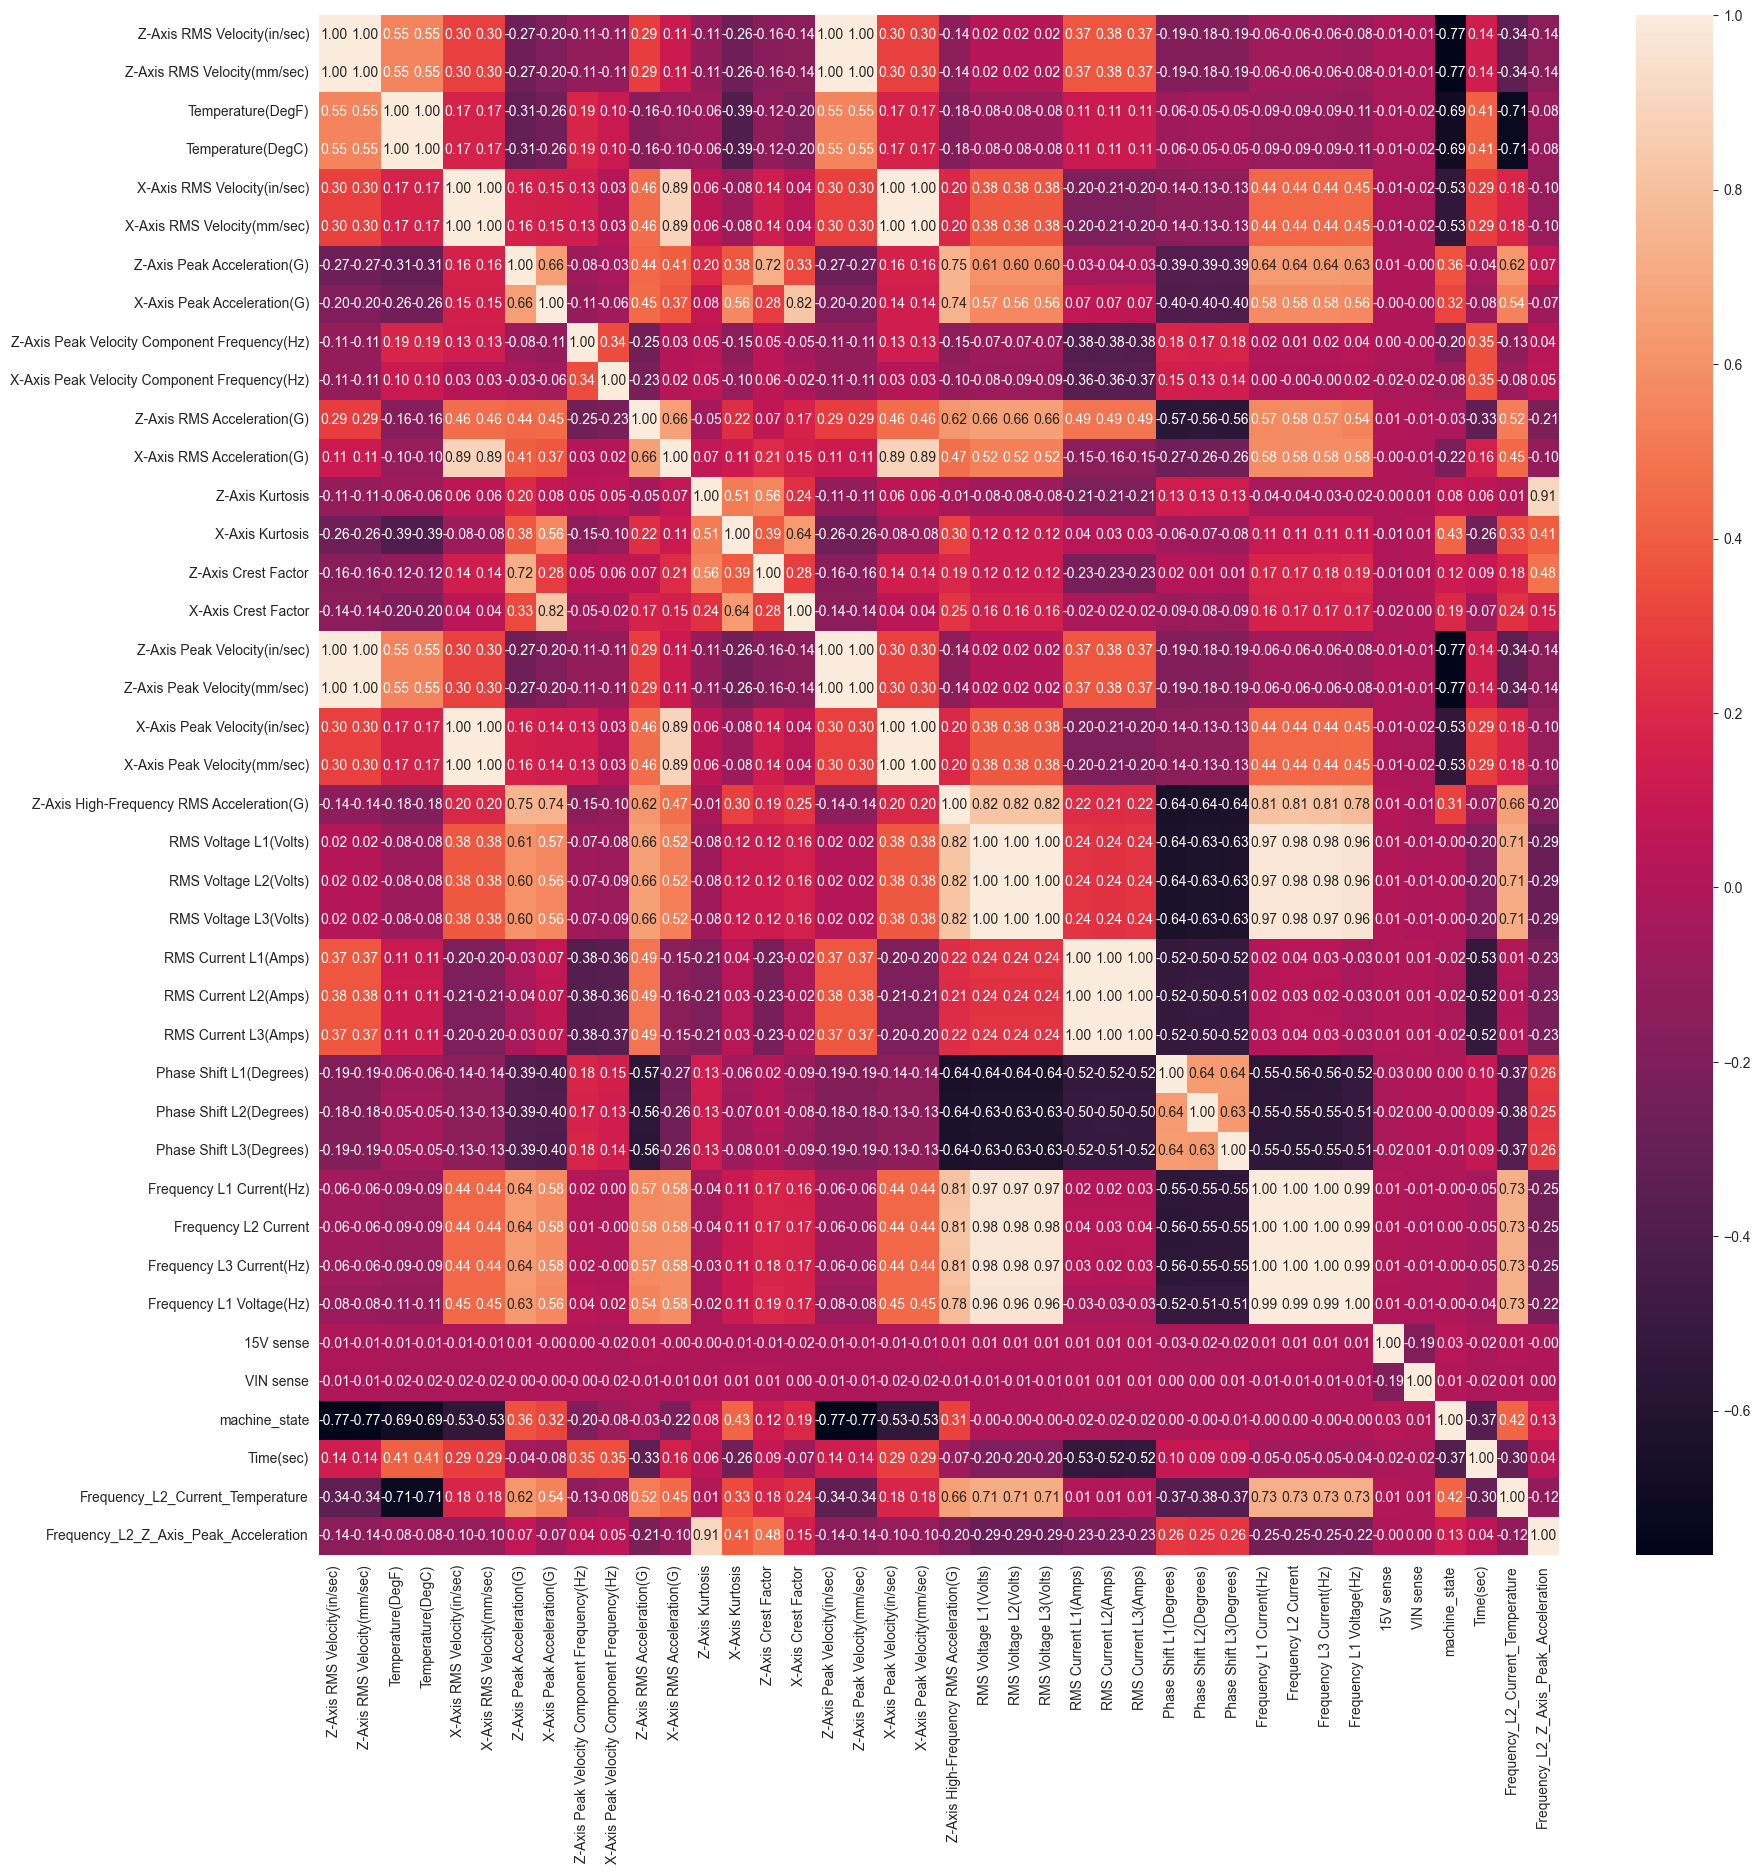

In [17]:
correlation_matrix = train_data.corr(numeric_only=True)
# plt the correlation matrix as a heatmap for better visualization with big image
plt.figure(figsize=(20, 20))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f")

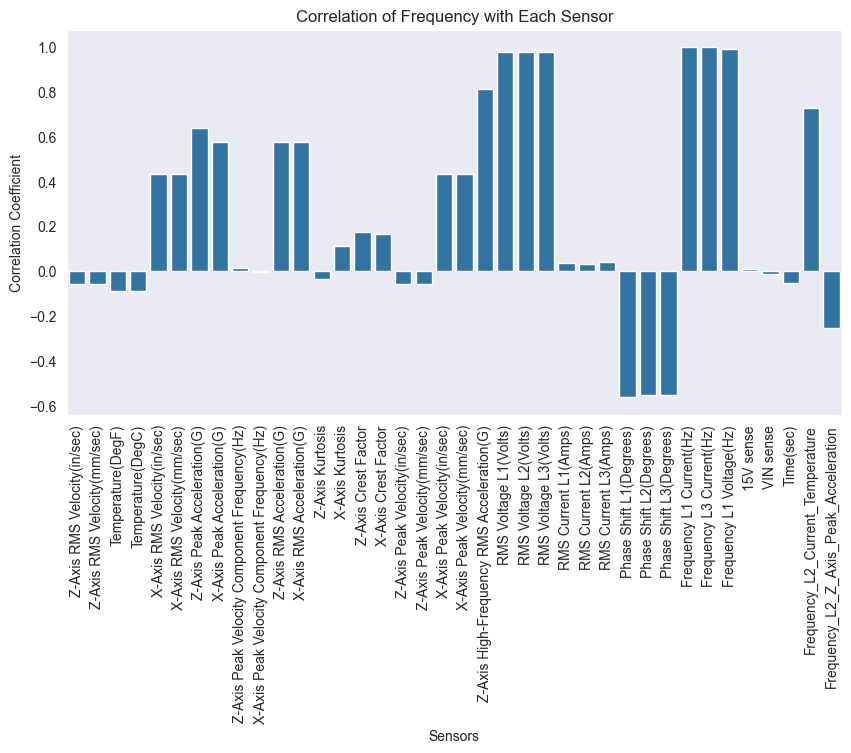

In [18]:
# correlation analysis for frequency

correlation_matrix_frequency = correlation_matrix['Frequency L2 Current']
correlation_matrix_frequency = correlation_matrix_frequency.drop('machine_state')
sns.barplot(x=correlation_matrix_frequency.drop('Frequency L2 Current').index, y=correlation_matrix_frequency.drop('Frequency L2 Current').values)
plt.title('Correlation of Frequency with Each Sensor')
plt.xlabel('Sensors')
plt.ylabel('Correlation Coefficient')
plt.xticks(rotation=90)  # Rotate labels for better readability
plt.show()

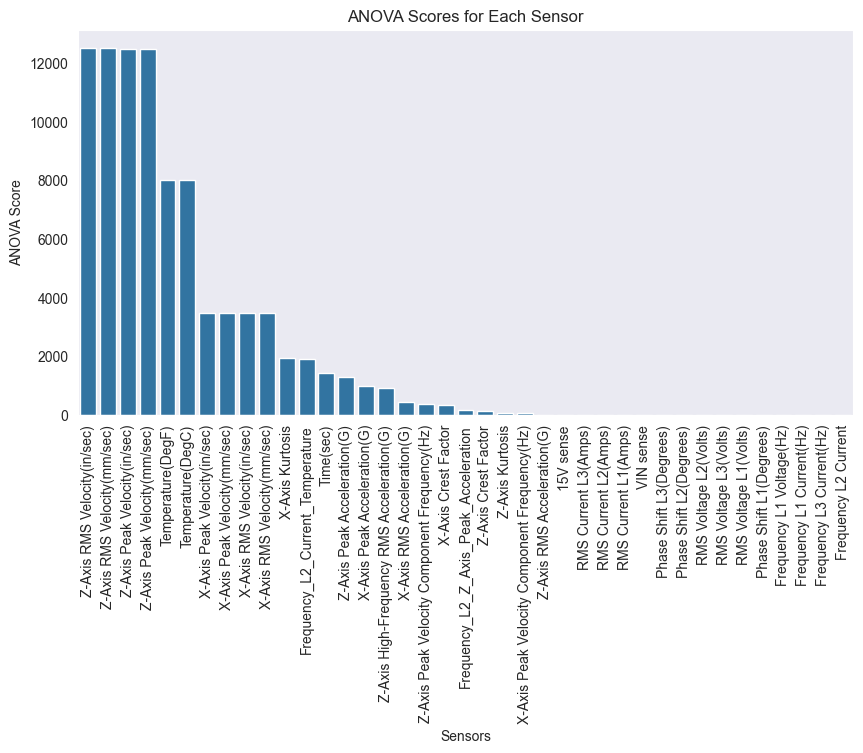

In [19]:
# ANOVA
selector = SelectKBest(f_classif, k='all')
selector.fit(X_scaled, y)
scores = selector.scores_

feature_scores = pd.DataFrame({
    'Feature': X.columns,
    'Score': scores
})

feature_scores = feature_scores.sort_values(by='Score', ascending=False)
sns.barplot(x=feature_scores['Feature'], y=feature_scores['Score'])
plt.title('ANOVA Scores for Each Sensor')
plt.xlabel('Sensors')
plt.ylabel('ANOVA Score')
plt.xticks(rotation=90)  # Rotate labels for better readability
plt.show()
